In [8]:
import pandas as pd
import os
import glob  # busca archivos con patrones usando comodines como en bash
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")

print("Path to dataset files:", path)

ModuleNotFoundError: No module named 'kagglehub'

## Dataset: CIC-IDS2017

El dataset CIC-IDS2017 (Canadian Institute for Cybersecurity) está dividido en **8 archivos CSV**, cada uno correspondiente a un día de la semana de captura de tráfico de red, generado con la herramienta CICFlowMeter a partir de capturas `.pcap`.

Cada archivo representa un escenario distinto de tráfico:

- **Monday** — tráfico completamente benigno (día de referencia, sin ataques)
- **Tuesday** — tráfico benigno + ataques de fuerza bruta (FTP-Patator, SSH-Patator)
- **Wednesday** — tráfico benigno + ataques DoS/DDoS (Hulk, GoldenEye, Slowloris, Slowhttptest) y Heartbleed
- **Thursday** — tráfico benigno + ataques web (SQL Injection, XSS, Brute Force) e infiltración
- **Friday** — tráfico benigno + Botnet, PortScan y DDoS (LOIT)

Se concatenaron los 8 archivos en un único dataframe porque, para entrenar un modelo de clasificación **multiclase**, se necesita tener representados todos los tipos de ataque (y el tráfico benigno) en un mismo conjunto de datos. Cada fila del dataframe resultante es un **flujo de red** (no un paquete individual), caracterizado por ~78 features estadísticas (duración, bytes por segundo, flags TCP, etc.) más una columna `Label` que indica si es tráfico benigno o el tipo de ataque específico.

Esta unificación es el punto de partida para el resto del proyecto: EDA, limpieza, y entrenamiento de los modelos base (Random Forest, XGBoost, MLP).

In [ ]:
print(os.listdir(path))
csv_files = glob.glob(os.path.join(path, "*.csv"))

dfs = [pd.read_csv(f) for f in csv_files]

# verificar que todos tengan las mismas columnas
for i, d in enumerate(dfs):
    d.columns = d.columns.str.strip()
    print(i, d.shape, "Mismas columnas?:", set(d.columns) == set(dfs[0].columns))
# concatenar los 8 csv's
df = pd.concat(dfs, ignore_index=True)
print("hola mundo")

['Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']
0 (286467, 79) Mismas columnas?: True
1 (170366, 79) Mismas columnas?: True
2 (445909, 79) Mismas columnas?: True
3 (225745, 79) Mismas columnas?: True
4 (529918, 79) Mismas columnas?: True
5 (191033, 79) Mismas columnas?: True
6 (288602, 79) Mismas columnas?: True
7 (692703, 79) Mismas columnas?: True
hola mundo


In [ ]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,22,1266342,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,22,1319353,41,44,2664,6954,456,0,64.975610,109.864573,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,22,160,1,1,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,22,1303488,41,42,2728,6634,456,0,66.536585,110.129945,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,35396,77,1,2,0,0,0,0,0.000000,0.000000,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
print(df.columns)
df.isna().sum()  # revisar valores nuloe

Index(['Destination Port', 'Flow Duration', 'Total Fwd Packets',
       'Total Backward Packets', 'Total Length of Fwd Packets',
       'Total Length of Bwd Packets', 'Fwd Packet Length Max',
       'Fwd Packet Length Min', 'Fwd Packet Length Mean',
       'Fwd Packet Length Std', 'Bwd Packet Length Max',
       'Bwd Packet Length Min', 'Bwd Packet Length Mean',
       'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s',
       'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
       'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max',
       'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std',
       'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags',
       'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length',
       'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s',
       'Min Packet Length', 'Max Packet Length', 'Packet Length Mean',
       'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count',
       'SYN Flag Co

,0
Destination Port,0
Flow Duration,0
Total Fwd Packets,0
Total Backward Packets,0
Total Length of Fwd Packets,0
...,...
Idle Mean,0
Idle Std,0
Idle Max,0
Idle Min,0


In [ ]:
pd.DataFrame(
    {
        "conteo": df["Label"].value_counts(),
        "porcentaje": df["Label"].value_counts(normalize=True) * 100,
    }
)

,conteo,porcentaje
Label,,
BENIGN,2273097,80.300366
DoS Hulk,231073,8.162981
PortScan,158930,5.614427
DDoS,128027,4.522735
DoS GoldenEye,10293,0.363615
FTP-Patator,7938,0.280421
SSH-Patator,5897,0.208320
DoS slowloris,5796,0.204752
DoS Slowhttptest,5499,0.194260


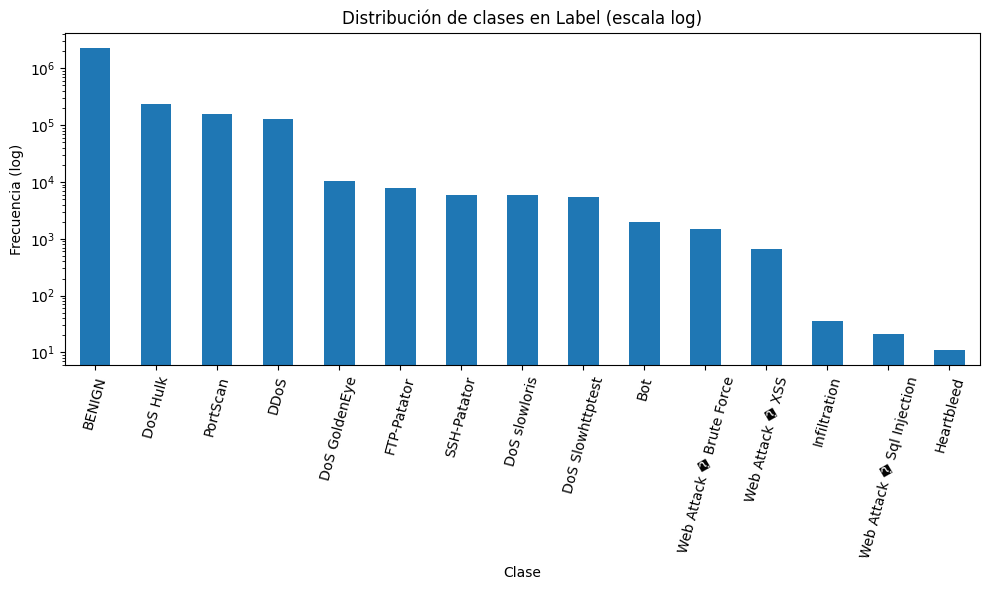

In [ ]:
conteo = df["Label"].value_counts()

plt.figure(figsize=(10, 6))
conteo.plot(kind="bar", logy=True)
plt.title("Distribución de clases en Label (escala log)")
plt.xlabel("Clase")
plt.ylabel("Frecuencia (log)")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [ ]:
labels_unicos = df["Label"].unique()
mapa_labels = {label: i for i, label in enumerate(labels_unicos)}

df["Label_encoded"] = df["Label"].map(mapa_labels)

print(mapa_labels)  # para ver qué número corresponde a cada clase

{'BENIGN': 0, 'PortScan': 1, 'Web Attack � Brute Force': 2, 'Web Attack � XSS': 3, 'Web Attack � Sql Injection': 4, 'FTP-Patator': 5, 'SSH-Patator': 6, 'DDoS': 7, 'Bot': 8, 'Infiltration': 9, 'DoS slowloris': 10, 'DoS Slowhttptest': 11, 'DoS Hulk': 12, 'DoS GoldenEye': 13, 'Heartbleed': 14}


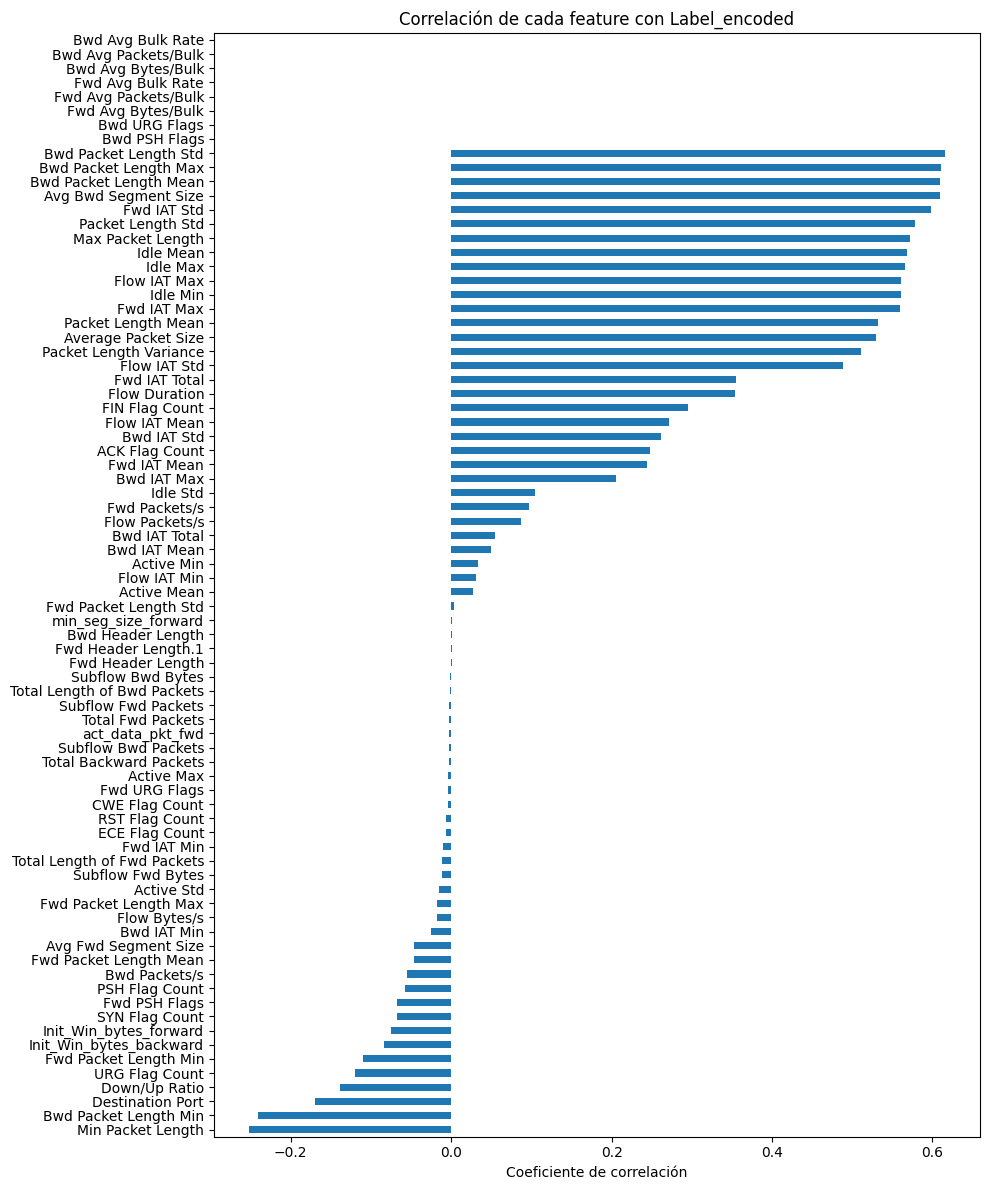

In [ ]:
# @title **CODE:** Grafico de barras para la correlacion completa
df_corr = df.select_dtypes(include="number").copy()
corr = df_corr.corr()
corr_target = corr["Label_encoded"].drop("Label_encoded").sort_values()
plt.figure(figsize=(10, 12))
corr_target.plot(kind="barh")
plt.title("Correlación de cada feature con Label_encoded")
plt.xlabel("Coeficiente de correlación")
plt.tight_layout()
plt.show()

In [ ]:
mask = (corr["Label_encoded"] > 0.5) | (corr["Label_encoded"] < -0.5)
columnas_relevantes = corr["Label_encoded"][
    mask
].index  # columnas con mayor correlacion con respecto a Label

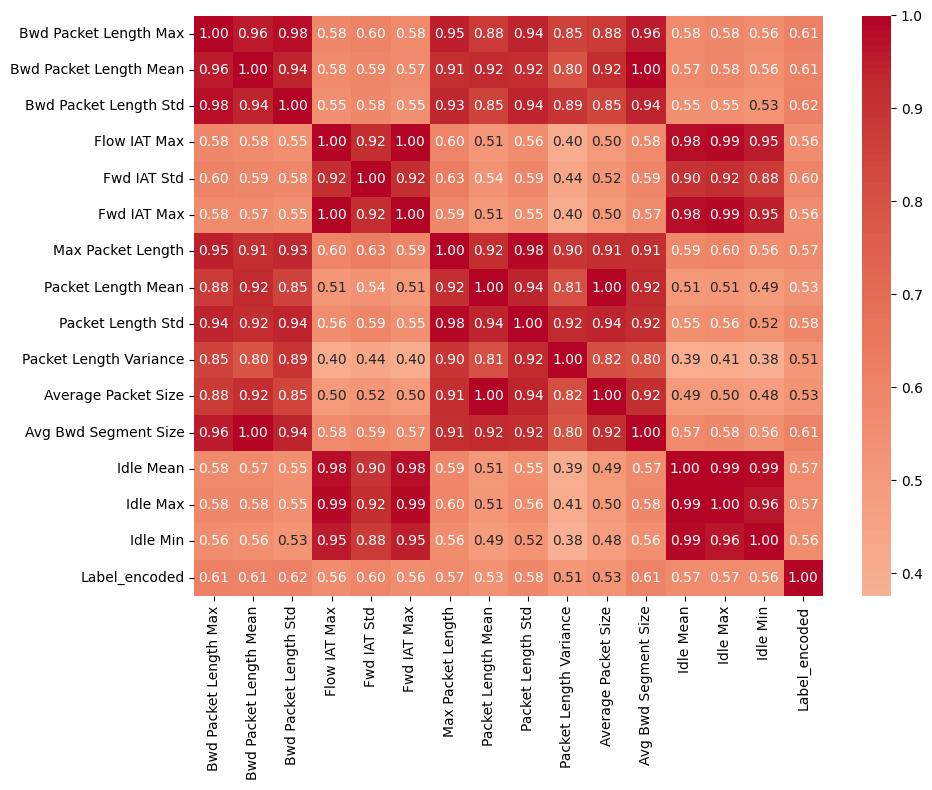

In [ ]:
# @title **CODE:** Correlacion de prueba para datos redundantes
corr_reducida = corr.loc[columnas_relevantes, columnas_relevantes]
plt.figure(figsize=(10, 8))
sns.heatmap(corr_reducida, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.tight_layout()
plt.show()

In [ ]:
df = df.drop(columns=["Avg Bwd Segment Size", "Average Packet Size"], errors="ignore")
df = df.drop(columns=["Fwd IAT Max", "Idle Max", "Idle Min"], errors="ignore")
df = df.drop(
    columns=[
        "Bwd Packet Length Max",
        "Bwd Packet Length Mean",
        "Max Packet Length",
        "Packet Length Mean",
        "Packet Length Std",
    ],
    errors="ignore",
)
# limpieza de caracteristicas

In [ ]:
columnas_relevantes = columnas_relevantes.drop(
    [
        "Avg Bwd Segment Size",
        "Label_encoded",
        "Average Packet Size",
        "Fwd IAT Max",
        "Idle Max",
        "Idle Min",
        "Bwd Packet Length Max",
        "Bwd Packet Length Mean",
        "Max Packet Length",
        "Packet Length Mean",
        "Packet Length Std",
    ],
    errors="ignore",
)
print(columnas_relevantes)

Index(['Bwd Packet Length Std', 'Flow IAT Max', 'Fwd IAT Std',
       'Packet Length Variance', 'Idle Mean'],
      dtype='object')


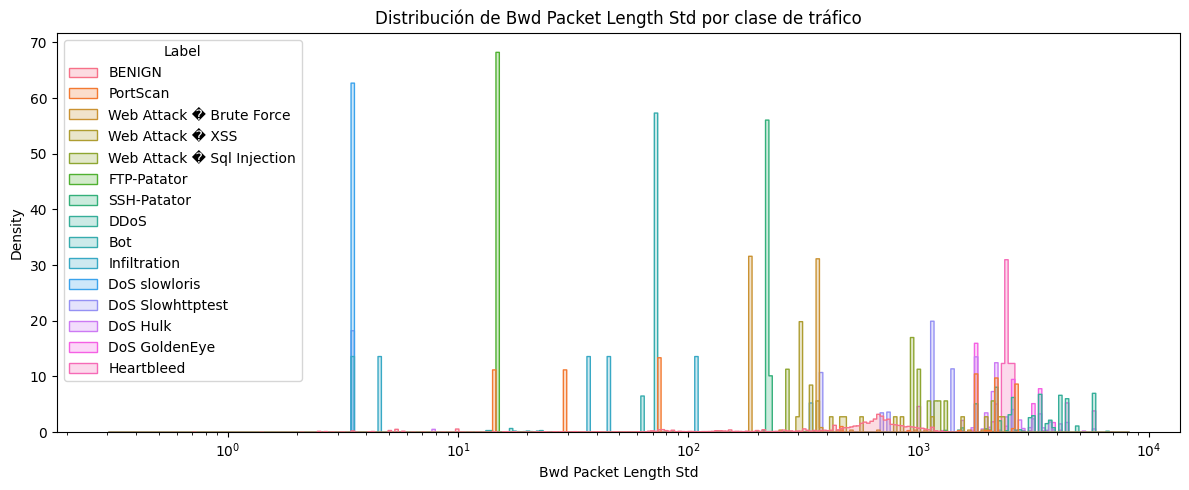

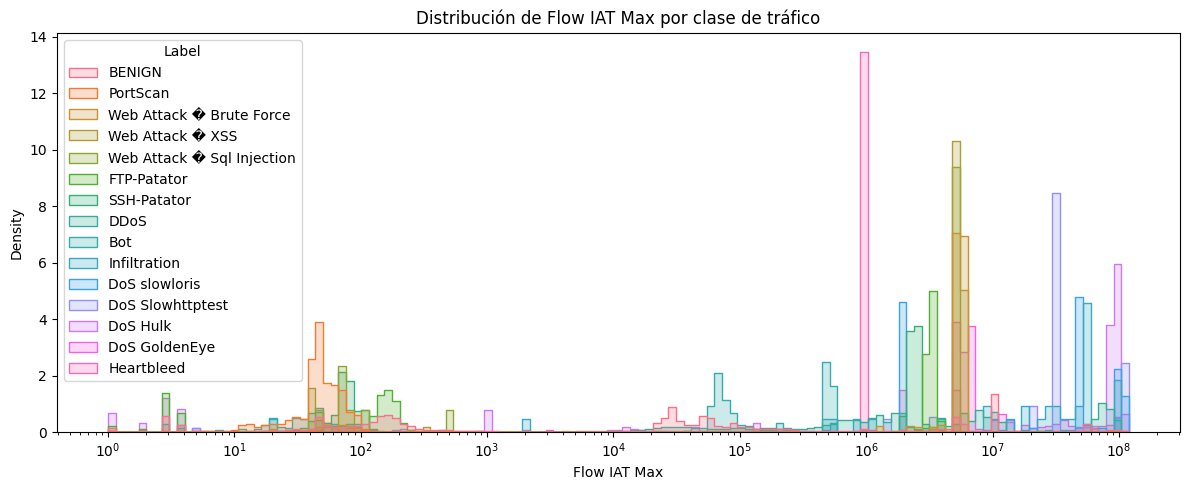

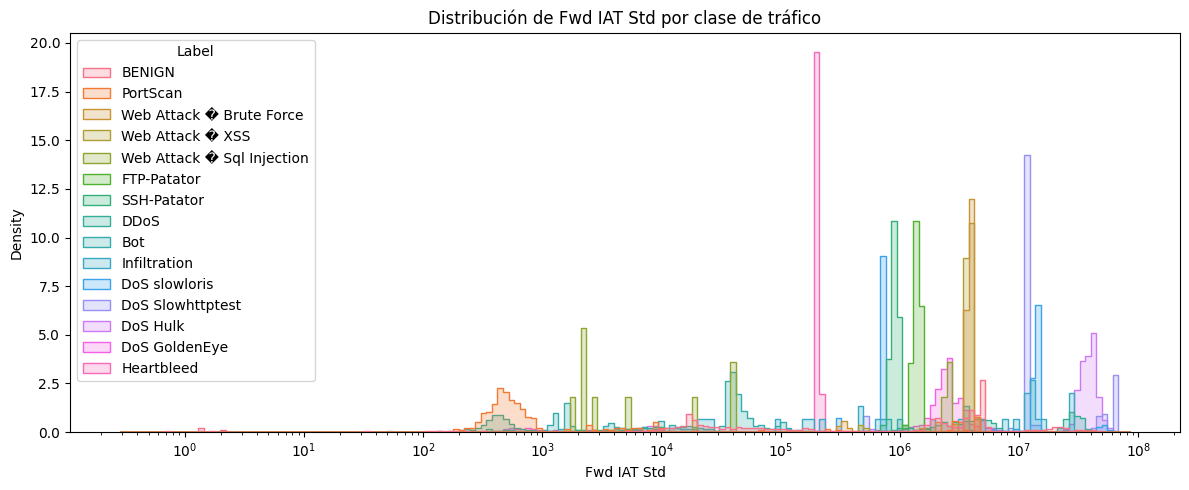

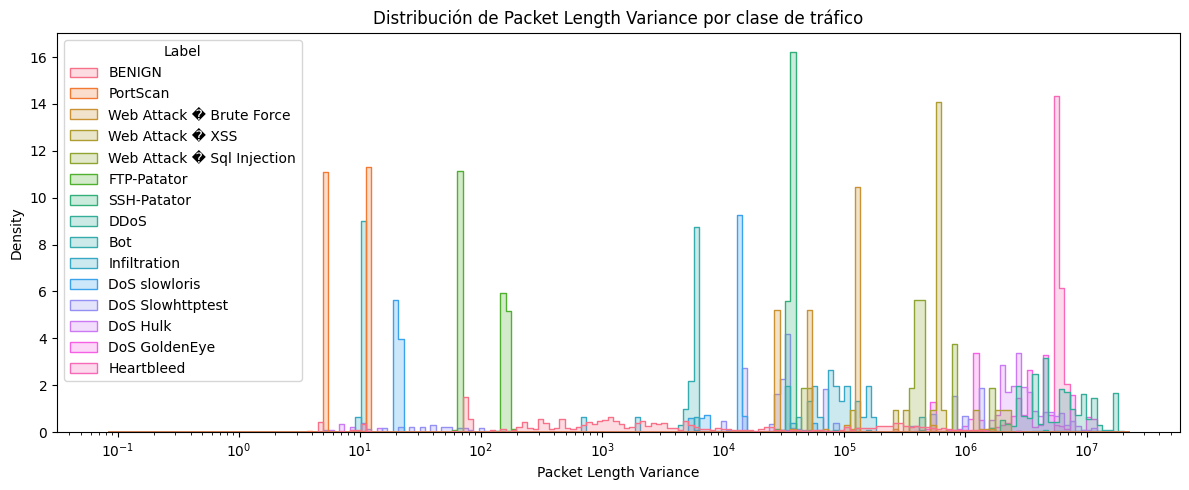

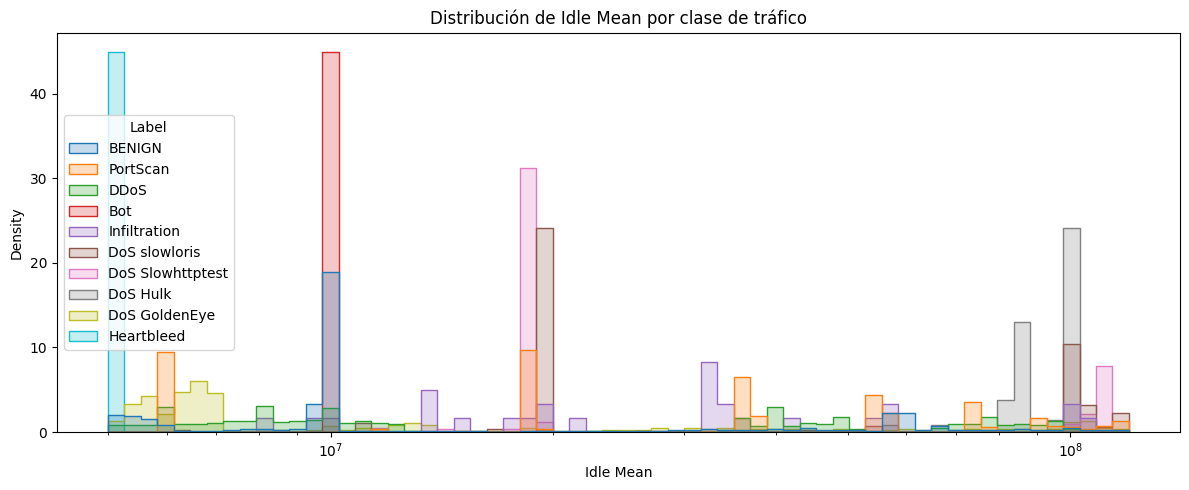

In [ ]:
for col in columnas_relevantes:
    plt.figure(figsize=(12, 5))

    # filtramos valores > 0 para poder usar log
    subset = df[df[col] > 0]

    sns.histplot(
        data=subset,
        x=col,
        hue="Label",
        log_scale=True,
        element="step",
        stat="density",
        common_norm=False,
    )

    plt.title(f"Distribución de {col} por clase de tráfico")
    plt.tight_layout()
    plt.show()

In [ ]:
for col in columnas_relevantes:
    stats = df.groupby("Label")[col].agg(  # agrupa las filas por clase de trafico
        mediana="median", q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
    )
    stats["IQR"] = stats["q3"] - stats["q1"]

    print(f"\n=== {col} ===")
    print(stats)


=== Bwd Packet Length Std ===
                                mediana           q1           q3          IQR
Label                                                                         
BENIGN                         0.000000     0.000000     0.000000     0.000000
Bot                            0.000000     0.000000    72.231111    72.231111
DDoS                        2189.772933     0.000000  3346.363967  3346.363967
DoS GoldenEye               1762.500000     0.000000  3185.599598  3185.599598
DoS Hulk                    1894.680443     0.000000  2277.232520  2277.232520
DoS Slowhttptest               0.000000     0.000000     0.000000     0.000000
DoS slowloris                  0.000000     0.000000     3.464102     3.464102
FTP-Patator                   14.549750     0.000000    14.549750    14.549750
Heartbleed                  2374.669707  2364.989694  2451.401636    86.411942
Infiltration                   0.000000     0.000000     0.000000     0.000000
PortScan             

In [ ]:
from sklearn.model_selection import train_test_split

df["Label_bin"] = (df["Label"] != "BENIGN").astype(int)
df["Label_bin"][df["Label_bin"] != 0]

,Label_bin
1463,1
1467,1
1468,1
1480,1
1511,1
...,...
2830646,1
2830653,1
2830692,1
2830721,1


In [ ]:
idx_tr, idx_te = train_test_split(
    df.index, test_size=0.2, stratify=df["Label_bin"], random_state=67
)
train = df.loc[idx_tr]

corr = (
    train.select_dtypes("number")
    .corr()["Label_bin"]
    .drop(["Label_bin", "Label_encoded"], errors="ignore")
)
cols = corr[corr.abs() > 0.5].index

X_train, Y_train = train[cols].values, train["Label_bin"].values
X_test, Y_test = df.loc[idx_te, cols].values, df.loc[idx_te, "Label_bin"].values

In [ ]:
from sklearn.base import clone
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

SEED = 67

In [ ]:
X_test.shape

In [ ]:
def metric_row(name, y_true, y_pred):
    return {
        "Modelo": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train, Y_train)

tows = []
tows.append(metric_row("GNB", Y_test, gnb.predict(X_test)))
print(tows)

dt = DecisionTreeClassifier(max_depth=3)
dt.fit(X_train, Y_train)

cows = []
cows.append(metric_row("DecisionTree", Y_test, dt.predict(X_test)))
cows

In [ ]:
# @title EXPLORACION DE HIPERPARAMETROS

depths = [1, 2, 4, 8, None]  # rango hecho en clase
depthsC = [
    5,
    10,
    15,
    20,
    30,
    None,
]  # rango sugerido por claude pero no se que tan viable sea


for depth in depths:

    dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    dt.fit(X_train, Y_train)
    y_pred = dt.predict(X_test)
    y_pred_train = dt.predict(X_train)

    print(f"The validation accuracy is:  {accuracy_score(Y_test, y_pred):.3f}")
    accuracy_train = pd.Series()

    print(f"The train accuracy is:  {accuracy_score(Y_train, y_pred_train):.3f}")
    accuracy_val = pd.Series()

    print(metric_row(f"DECISIONTREE depth: {depth}", Y_test, dt.predict(X_test)))


print(f"La profundidad con mas accuracy de validacion es: {accuracy_val.max()}")

minleafs = [
    1,
    2,
    5,
    10,
    20,
    50,
]  # aca esta por si quiere explorar esto tambien (estos valores me los dio claude)
# for leafs in minleafs:

#   dt = DecisionTreeClassifier(min_samples_leaf=leafs, random_state=SEED) #como el mejor depth es nan y ese es el default lo dejo asi
#   dt.fit(X_train, Y_train)
#   y_pred = dt.predict(X_test)
#   y_pred_train = dt.predict(X_train)

#   print(f"The validation accuracy is:  {accuracy_score(Y_test, y_pred):.3f}")
#   accuracy_train = pd.Series()


#   print(f"The train accuracy is:  {accuracy_score(Y_train, y_pred_train):.3f}")
#   accuracy_val = pd.Series()


#   print(metric_row(f'DECISIONTREE minleafs: {leafs}', Y_test, dt.predict(X_test)))


# print(f"Las hojas minimas con mas accuracy de validacion es: {accuracy_val.max()}")

In [ ]:
n_trees = [10, 50, 100, 200]  # rango de la clase
n_treesC = [100, 200, 300, 500]  # rango de claudia pero ush no me da miedo tanto arbol

for trees in n_trees:

    rf = RandomForestClassifier(n_estimators=trees, random_state=SEED, n_jobs=-1)
    rf.fit(X_train, Y_train)
    y_pred = rf.predict(X_test)
    y_pred_train = rf.predict(X_train)

    print(f"The validation accuracy is:  {accuracy_score(Y_test, y_pred):.3f}")
    accuracy_train = pd.Series()

    print(f"The train accuracy is:  {accuracy_score(Y_train, y_pred_train):.3f}")
    accuracy_val = pd.Series()

    print(metric_row(f"RANDOMFOREST trees: {trees}", Y_test, rf.predict(X_test)))

best = accuracy_val.max()
print(f"La profundidad con mas accuracy de validacion es: {accuracy_val.max()}")

depths = [1, 2, 4, 8, None]  # rango hecho en clase para DecisionTree
depthsC = [
    5,
    10,
    15,
    20,
    30,
    None,
]  # rango sugerido por claude (el mismo para DT) pero no se que tan viable sea
# for depth in depths:

#   rf = RandomForestClassifier(n_estimators=best, max_depth = depth, random_state=SEED)
#   dt.fit(X_train, Y_train)
#   y_pred = dt.predict(X_test)
#   y_pred_train = dt.predict(X_train)

#   print(f"The validation accuracy is:  {accuracy_score(Y_test, y_pred):.3f}")
#   accuracy_train = pd.Series()


#   print(f"The train accuracy is:  {accuracy_score(Y_train, y_pred_train):.3f}")
#   accuracy_val = pd.Series()


#   print(metric_row(f'RANDOMFOREST depth: {depth}', Y_test, dt.predict(X_test)))


# print(f"La profundidad con mas accuracy de validacion es: {accuracy_val.max()}")

In [ ]:
# mejorar el rendimiento del codigo de aqui pa abajo xddd
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = make_pipeline(StandardScaler(), SVC(cache_size=500, random_state=SEED))
grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["rbf", "linear", "poly"],
    "svc__gamma": ["scale"],
}
gs = GridSearchCV(
    pipe, grid, cv=3, scoring="accuracy", n_jobs=8, return_train_score=True
)
gs.fit(X_train, Y_train)

print(gs.best_params_, gs.best_score_)
res = pd.DataFrame(gs.cv_results_)[
    [
        "param_svc__C",
        "param_svc__kernel",
        "mean_train_score",
        "mean_test_score",
        "mean_fit_time",
    ]
]
print(res.sort_values("mean_test_score", ascending=False))

y_pred = gs.predict(X_test)  # una sola vez, al final
print(metric_row("SVM mejor", Y_test, y_pred))

In [ ]:
# @title ACA ESTA HECHO POR CLAUDE POR SI LA FORMA COMO LO HICE NO ES LO SUFICIENTEMENTE RIGUROSA O ALGO ASI
# igual como lo hice yo es como lo hicimos en clase

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


def submuestra(n):
    Xs, _, ys, _ = train_test_split(
        X_train, Y_train, train_size=n, stratify=Y, random_state=SEED
    )
    return Xs, ys


# nombre: (modelo, espacio, submuestra, n_iter, n_jobs de la búsqueda)
busquedas = {
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {
            "criterion": ["gini", "entropy"],
            "max_depth": [5, 10, 15, 20, 30, None],
            "min_samples_leaf": [1, 2, 5, 10, 20, 50],
            "class_weight": [None, "balanced"],
        },
        submuestra(100_000),
        30,
        -1,
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
        {
            "max_depth": [10, 20, 30, None],
            "min_samples_leaf": [1, 2, 5, 10],
            "max_features": ["sqrt", "log2", 0.3],
            "class_weight": [None, "balanced", "balanced_subsample"],
            "max_samples": [0.3, 0.5, None],
        },
        submuestra(100_000),
        15,
        1,
    ),  # n_jobs=1: el bosque ya usa todos los núcleos
    "SVM": (
        make_pipeline(StandardScaler(), SVC()),
        {
            "svc__kernel": ["rbf"],
            "svc__C": loguniform(1e-1, 1e2),
            "svc__gamma": loguniform(
                1e-4, 1e0
            ),  # esto de loguniform no se muy bien para que es pero bueno
            "svc__class_weight": [None, "balanced"],
        },
        submuestra(15_000),
        20,
        -1,
    ),  # el SVM es lento: submuestra pequeña
}

mejores = {}
for nombre, (modelo, espacio, (Xs, ys), n_iter, nj) in busquedas.items():
    b = RandomizedSearchCV(
        modelo,
        espacio,
        n_iter=n_iter,
        cv=cv,
        scoring="f1_macro",
        n_jobs=nj,
        random_state=42,
        verbose=1,
    )  # verbous
    b.fit(Xs, ys)
    mejores[nombre] = b
    print(f"{nombre}: F1 macro CV = {b.best_score_:.4f}  {b.best_params_}")

In [ ]:
# @title LOS MODELOS PARA BINARIO

candidates = {
    "GNB": GaussianNB(),
    "DT": DecisionTreeClassifier(
        max_depth=None, random_state=SEED
    ),  # max_depth = nan segun la exploracion
    "RF": RandomForestClassifier(
        n_estimators=2, random_state=SEED, n_jobs=-1
    ),  # n_estimators = 200 segun la exploracion #(lo mas calidad precio segun claude)
    "SVM": make_pipeline(StandardScaler(), SVC(C=1, gamma="scale")),
}  # C=10?, kernel = 'rbf' segun la exploracion (todavia falta hacer la exploracion pero confio en rbf la cabra)

rows = []  # aca hacemos todos los modelos con label_bin, en teoria
for name, estimator in candidates.items():
    model = clone(estimator)
    model.fit(X_train, Y_train)
    rows.append(metric_row(name, Y_test, model.predict(X_test)))

validation_results = (
    pd.DataFrame(rows).set_index("Modelo").sort_values(by=["F1"], ascending=False)
)
display(validation_results.round(3))
selected_names = validation_results[:2].index  # en teoria salen los mejores 2
print(
    f"Modelos seleccionados por F1 de validación: {selected_names}"
)  # de aca sacamos los modelos para trabajar con multiclase

In [ ]:
# @title Voy a tratar de combinar labels
hmm = pd.DataFrame(
    {
        "conteo": df["Label_encoded"].value_counts(),
        "porcentaje": df["Label_encoded"].value_counts(normalize=True) * 100,
    }
)
hmm["conteo"]
hmm.sort_values(by="porcentaje", ascending=True)

In [ ]:
porcentaje = df["Label_encoded"].value_counts(normalize=True) * 100
porcentaje.sort_values(ascending=True)
hmm.sort_values(by="porcentaje", ascending=True)

for porcentaje in hmm["porcentaje"].sort_values(ascending=True):
    print(porcentaje)
    if porcentaje < 1:  # <- creo que esto ni sirvio xd
        hmm["conteo_acum"] = hmm["conteo"].sort_values(ascending=True).cumsum()
        hmm["porcentaje_acum"] = hmm["porcentaje"].sort_values(ascending=True).cumsum()
hmm.sort_values(by="porcentaje", ascending=True)

In [ ]:
Xmulti = df[columnas_relevantes].values
Ymulti = df["Label_multi"].values  # el Label_multi toca hacerlo


Xmulti_train, Xmulti_test, Ymulti_train, Ymulti_test = train_test_split(
    Xmulti, Ymulti, test_size=0.2, random_state=SEED, shuffle=True, stratify=Ymulti
)

In [ ]:
# @title Suponiendo que funcione igual ya quedaria solo encontrar Label_multi
bestcandidates = {
    "RF": RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=-1
    ),  # probablemente estos 2 sean los mejores
    "SVM": make_pipeline(StandardScaler(), SVC(C=1, gamma="scale")),
}

bows = []  # aca hacemos los mejores modelos con label_multi, en teoria
for name, estimator in bestcandidates.items():
    model = clone(estimator)
    model.fit(X_train, Y_train)
    bows.append(metric_row(name, Y_test, model.predict(X_test)))

validation_results = (
    pd.DataFrame(rows).set_index("Modelo").sort_values(by=["F1"], ascending=False)
)
display(validation_results.round(3))

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

SEED = 68
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

SEED = 68

Xregression = df[columnas_relevantes].values

Yregression = df["Flow duration"].values
X_train, X_test, y_train, y_test = train_test_split(
    Xregression, Yregression, train_size=0.8, random_state=SEED
)


busquedas = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=42),
        {
            "criterion": ["gini", "entropy"],
            "max_depth": [5, 10, 15, 20, 30, None],
            "min_samples_leaf": [1, 2, 5, 10, 20, 50],
            "class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
        {
            "max_depth": [10, 20, 30, None],
            "min_samples_leaf": [1, 2, 5, 10],
            "max_features": ["sqrt", "log2", 0.3],
            "class_weight": [None, "balanced", "balanced_subsample"],
            "max_samples": [0.3, 0.5, None],
        },
    ),  # n_jobs=1: el bosque ya usa todos los núcleos
}


mejores = {}
for nombre, (modelo, espacio) in busquedas.items():
    b = RandomizedSearchCV(
        modelo,
        espacio,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
        random_state=SEED,
        verbose=1,
    )  # verbous
    b.fit(X_train, y_train)
    mejores[nombre] = b
    print(f"{nombre}: F1 macro CV = {b.best_score_:.4f}  {b.best_params_}")

In [ ]:
# @title Se viene con regrfesion

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

SEED = 67

Xregression = df[columnas_relevantes].values

Yregression = df["Flow duration"].values

Xtrainr, Xtestr, ytrainr, ytestr = train_test_split(
    Xregression, Yregression, test_size=0.2, stratify=Yregression, random_state=SEED
)

candidatesRegression = {
    "DT": DecisionTreeRegressor(
        max_depth=None, random_state=SEED
    ),  # max_depth = nan segun la exploracion
    "RF": RandomForestRegressorr(
        n_estimators=2, random_state=SEED, n_jobs=-1
    ),  # n_estimators = 200 segun la exploracion #(lo mas calidad precio segun claude)
}

rows = []  # aca hacemos todos los modelos con label_bin, en teoria
for name, estimator in candidates.items():
    model = clone(estimator)
    model.fit(X_train, Y_train)
    rows.append(metric_row(name, Y_test, model.predict(X_test)))

validation_results = (
    pd.DataFrame(rows).set_index("Modelo").sort_values(by=["F1"], ascending=False)
)
display(validation_results.round(3))
selected_names = validation_results[:2].index  # en teoria salen los mejores 2
print(
    f"Modelos seleccionados por F1 de validación: {selected_names}"
)  # de aca sacamos los modelos para trabajar con multiclase